# A：数据准备与交付检查

本 notebook 展示已处理的真实数据。默认不重新下载或扫描 2.53 亿条日志。

完整重建：在项目根目录依次运行 `scripts/download_data.py`、`scripts/prepare_data.py`、`scripts/inspect_splits.py`。详细规则见 `DATA_README.md`。

本次不训练 ALS、不拟合 TF-IDF，也不选择最终训练/验证/测试切分。

In [1]:
from pathlib import Path
import json
import duckdb
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
assert (ROOT / "reports/data_summary.json").exists(), "请先运行数据准备脚本"
DATA = ROOT / "data"
db = duckdb.connect()
summary = json.loads((ROOT / "reports/data_summary.json").read_text())
print(json.dumps(summary, ensure_ascii=False, indent=2))
print("原始转换保留全部事件；分析版排除 1 条孤立的 1970 年事件。")

{
  "content": {
    "tag_source_rows": 109269,
    "identical_tag_rows_removed": 983,
    "genre_source_rows": 109269,
    "identical_genre_rows_removed": 0,
    "tag_file_tracks": 108286,
    "empty_tag_tracks": 20194,
    "normalized_tag_pairs": 3643410,
    "format_collisions_merged": 0,
    "genre_file_tracks": 109269,
    "genre_dimensions": 685,
    "zero_genre_tracks": 27
  },
  "events": {
    "rows": 252984396,
    "seconds": 146.82,
    "parquet_bytes": 2101941974,
    "dropped_rows": 0,
    "deduplicated": false,
    "timezone": "unspecified in source; kept timezone-naive",
    "reused_in_this_run": true
  },
  "analysis_rows": 252984395,
  "excluded_pre2005_events": 1,
  "source_min_timestamp": "1970-01-01 01:00:36",
  "date_floor": "2005-01-01",
  "users": 119140,
  "tracks": 56512,
  "min_timestamp": "2005-02-14 01:07:46",
  "max_timestamp": "2020-03-20 12:59:51",
  "coverage": {
    "event_tracks": 56512,
    "event_tracks_with_positive_tags": 45589,
    "event_tracks_w

## 1. 收听记录

一行代表一次播放。`user_id` 是用户编号，`track_id` 是歌曲编号，`timestamp` 是源文件中的时间。重复听歌是有效行为。时间未附带时区，本次保持原样。

In [2]:
db.sql(f"SELECT * FROM read_parquet('{DATA}/samples/dev/events.parquet') LIMIT 10").show()

┌─────────┬──────────────────┬─────────────────────┐
│ user_id │     track_id     │      timestamp      │
│ varchar │     varchar      │      timestamp      │
├─────────┼──────────────────┼─────────────────────┤
│ 9458    │ b2HkpWTB4c3wNc5O │ 2012-09-14 02:36:14 │
│ 9458    │ g7SRwZ4d5kFwpMn7 │ 2012-09-14 02:31:16 │
│ 9458    │ AQZChkEQCmd9Yd6N │ 2012-09-14 01:15:48 │
│ 9458    │ TBpLrjCpvVvnQmjv │ 2012-09-13 23:32:51 │
│ 9458    │ cVlqgjKd0DWRGhtM │ 2012-08-05 06:32:48 │
│ 9458    │ lfzu6ogntqCXCOzw │ 2012-08-05 05:16:49 │
│ 9458    │ FtxO8NFDBiEwfPh9 │ 2012-08-05 03:52:04 │
│ 9458    │ ttsmDLXncIKZIgTc │ 2012-08-05 03:36:18 │
│ 9458    │ m6DSCmAPTk9BtRTz │ 2012-07-22 05:58:54 │
│ 9458    │ ROQzuZJGMK23oSCu │ 2012-07-14 04:28:41 │
└─────────┴──────────────────┴─────────────────────┘
  10 rows                                3 columns



## 2. 歌曲信息

一行代表一个歌曲 ID。`tags` 与 `tag_weights` 按位置对应；权重总和不要求为 100。`first_seen` 来自完整日志，不是抽样日志。标签文件中 983 条相同 ID、相同内容的重复记录已合并，防止连接后放大事件数。

In [3]:
rows = db.sql(f"SELECT track_id, tags, tag_weights, first_seen FROM read_parquet('{DATA}/samples/dev/tracks.parquet') WHERE has_tags LIMIT 3").fetchall()
for track, tags, weights, first_seen in rows:
    print("歌曲：", track, "全局首次出现：", first_seen)
    print("前 8 个标签：", list(zip(tags, weights))[:8])

歌曲： 02tlc7d6RtnNVG3P 全局首次出现： 2018-05-02 01:04:35
前 8 个标签： [('city pop', 50.0), ('dream pop', 50.0), ('hypnagogic pop', 50.0), ('indie pop', 50.0), ('indietronica', 100.0), ('synthpop', 100.0), ('twee pop', 50.0)]
歌曲： 03v7PvCepe2N5A6V 全局首次出现： 2007-08-28 15:04:07
前 8 个标签： [('amable animal', 34.0), ('animal songs', 34.0), ('dogs and cats', 34.0), ('don henley', 34.0), ('eclectonia', 34.0), ('female vocal', 34.0), ('folk', 100.0), ('full bodied voices', 34.0)]
歌曲： 06pbFHF18RwKu4t1 全局首次出现： 2007-10-02 09:10:56
前 8 个标签： [('00s', 6.0), ('1', 3.0), ('2', 3.0), ('2 of 10 stars', 3.0), ('6 of 10 stars', 3.0), ('acoustic', 12.0), ('alternative', 3.0), ('ambient', 3.0)]


## 3. 覆盖与样本

缺标签记录没有从完整日志中删除。所有模型最终要使用一致的评估集合。开发样本是 2,000 人，候选正式样本是 20,000 人；B 仍需按训练期历史筛选用户。

In [4]:
print("内容覆盖：", summary["coverage"])
print("样本规模：", summary["samples"])
for name in ["dev", "standard"]:
    ids = f"{DATA}/samples/{name}/users.parquet"
    events = f"{DATA}/samples/{name}/events.parquet"
    expected = db.sql(f"SELECT sum(event_count) FROM read_parquet('{DATA}/processed/user_stats.parquet') JOIN read_parquet('{ids}') USING(user_id)").fetchall()[0][0]
    actual = db.sql(f"SELECT count(*) FROM read_parquet('{events}')").fetchall()[0][0]
    assert expected == actual, "抽样用户的历史记录不完整"
    print(name, "记录完整性通过：", actual)
missing = db.sql(f"SELECT count(*) FROM (SELECT user_id FROM read_parquet('{DATA}/samples/dev/users.parquet') EXCEPT SELECT user_id FROM read_parquet('{DATA}/samples/standard/users.parquet'))").fetchall()[0][0]
assert missing == 0
print("开发用户集合包含在标准用户集合中")

内容覆盖： {'event_tracks': 56512, 'event_tracks_with_positive_tags': 45589, 'event_tracks_with_genres': 56498, 'event_tracks_with_both': 45577}
样本规模： {'dev': {'events': 4343429, 'users': 2000, 'tracks': 51472}, 'standard': {'events': 42978876, 'users': 20000, 'tracks': 56379}}
dev 记录完整性通过： 4343429
standard 记录完整性通过： 42978876
开发用户集合包含在标准用户集合中


## 4. 描述性 EDA

这些图使用全时期数据，只用于理解数据。不能将全时期听众数、用户活跃度或标签频率直接用于训练。

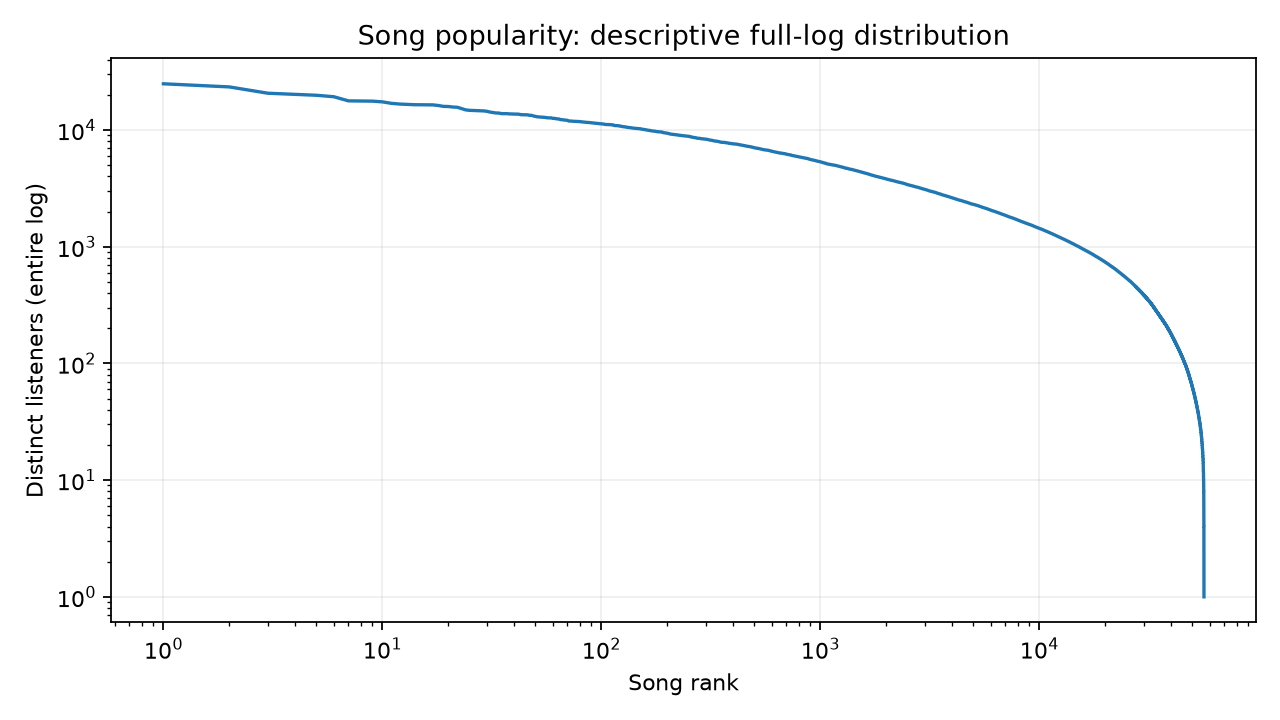

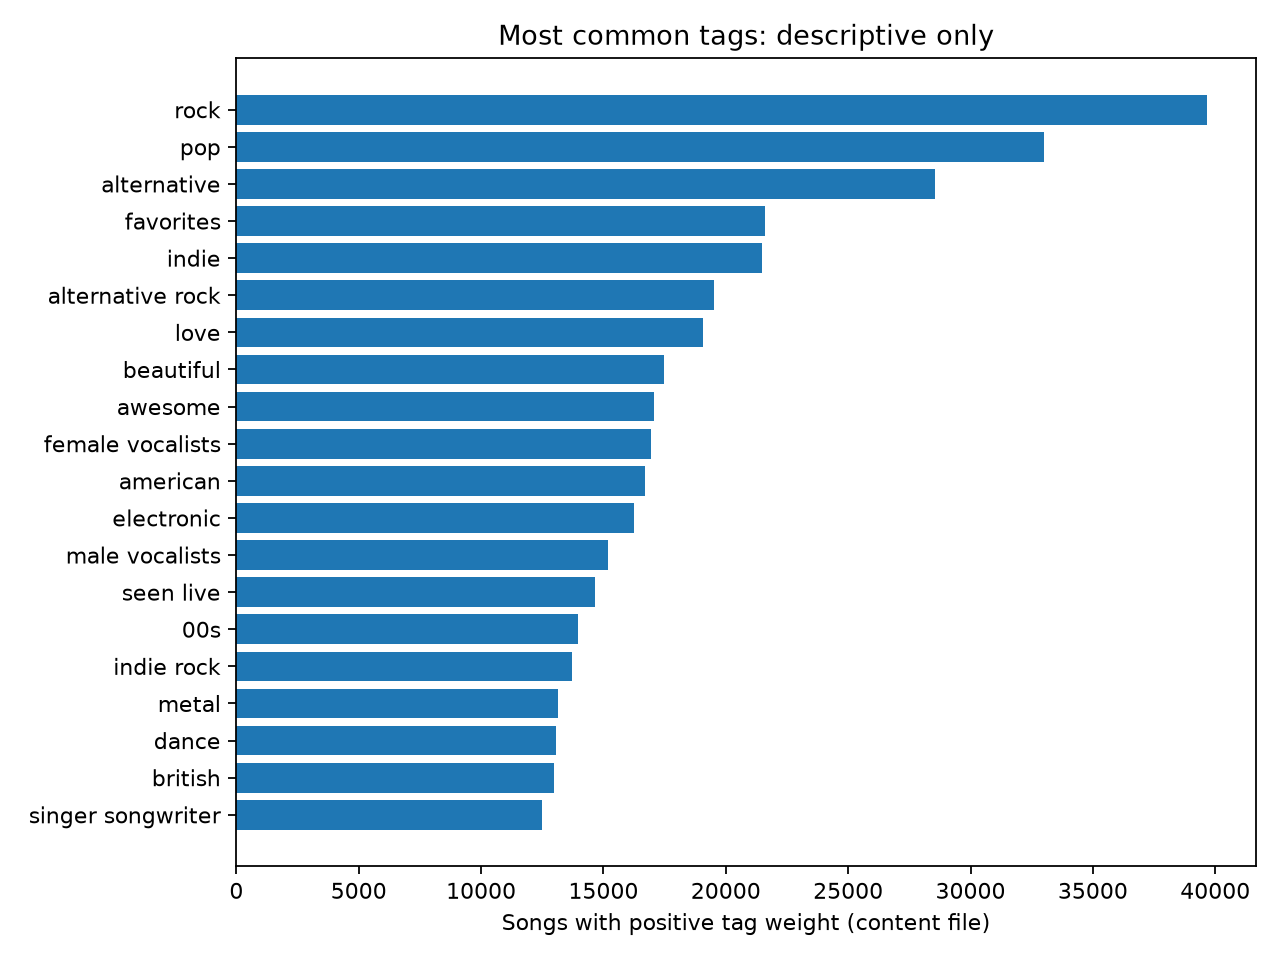

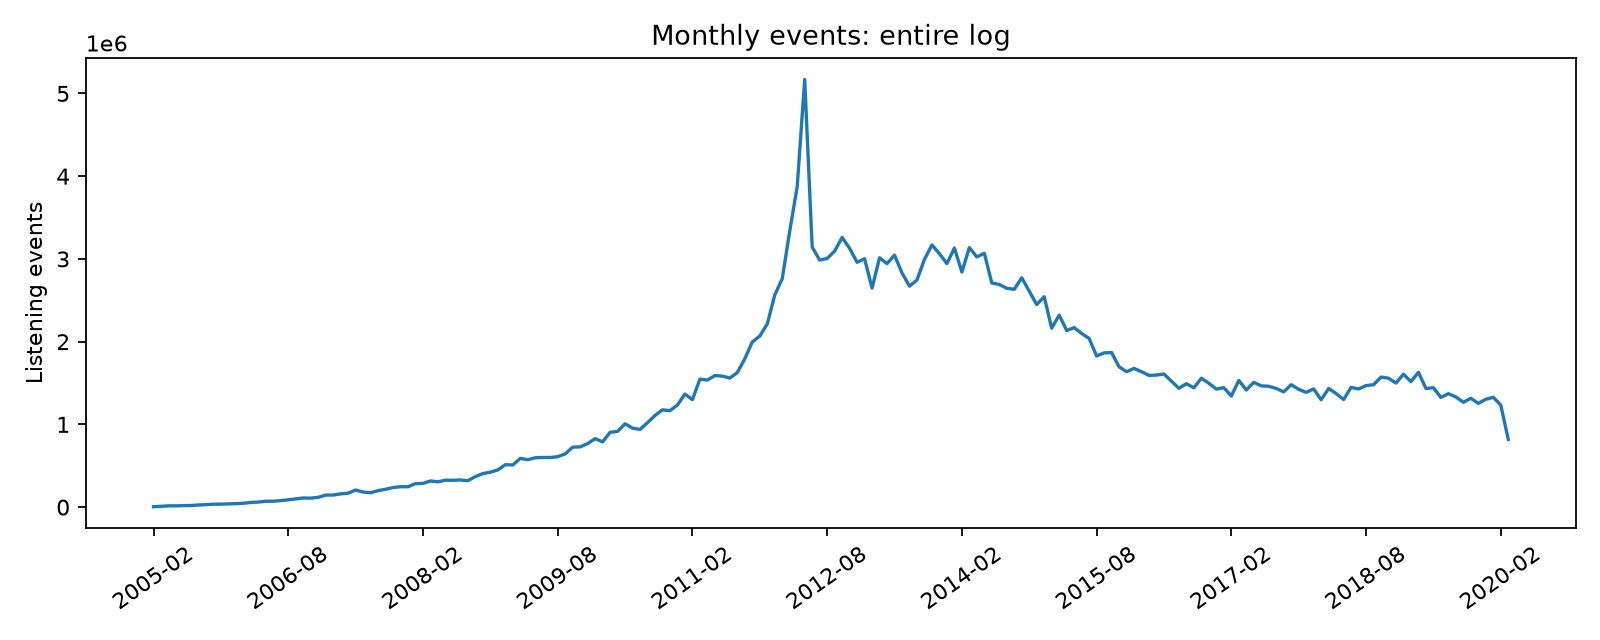

In [5]:
for name in ["song_popularity", "tag_frequency", "monthly_events"]:
    display(Image(filename=str(ROOT / "reports/figures" / f"{name}.png")))

## 5. 时间切分可行性

这里只统计候选日期，不确定最终 T。每个候选 T 的用户资格只由 T 前至少 20 首有标签歌曲的历史决定。新歌必须在全局日志中首次出现，并具有完整的 30 天观察期。

目标为新歌前 30 天的不同合格听众。本表未预留前 10 位听众，也未生成验证集或测试集。

In [6]:
db.sql(f"SELECT * FROM read_csv_auto('{ROOT}/reports/split_feasibility.csv')").show(max_rows=20)

┌────────────┬───────────────────────────┬──────────────────┬──────────┬────────────────┬───────────────────┬────────────────────┬──────────────────────┬──────────────────────┐
│     T      │ song_window_end_exclusive │ observation_days │  sample  │ eligible_users │ tagged_new_tracks │ songs_ge1_listener │ songs_ge10_listeners │ songs_ge20_listeners │
│    date    │           date            │      int64       │ varchar  │     int64      │       int64       │       int64        │        int64         │        int64         │
├────────────┼───────────────────────────┼──────────────────┼──────────┼────────────────┼───────────────────┼────────────────────┼──────────────────────┼──────────────────────┤
│ 2011-01-01 │ 2011-06-30                │               30 │ full     │          27344 │              1068 │               1019 │                  607 │                  459 │
│ 2011-01-01 │ 2011-06-30                │               30 │ dev      │            475 │              1068 │      

## 6. 接下来交给队友

- B：确定 T 与验证/测试窗口，筛选训练期用户，生成 `train_counts.parquet`、`split.json` 和评估函数。
- C：使用训练老歌的标签建立 MinHash LSH，不索引测试新歌作为老歌。
- D：接入 B 的 ALS 用户向量和 C 的候选池。

A 已提供原始文件校验、完整事件、清洗标签、流派、全局首次出现时间、嵌套用户样本、EDA 与数据说明。语义标签合并和稀有标签过滤暂不做；训练词表和 IDF 留到训练集确定后拟合。